# 05 - K-means done right (with a null model)

This is the idea you started with: cluster the individuals and see whether the
clusters correspond to nations. K-means minimizes the within-cluster sum of
squares:

$$ \sum_{k=1}^{K} \sum_{i \in C_k} \lVert x_i - \mu_k \rVert^2 $$

Two things make it a poor sole tool for genotype data:

1. It must be run on a dimension-reduced representation (we use PCA scores),
   and it will **always return K clusters**, even for perfectly continuous
   data.
2. It makes hard assignments, while human ancestry is often admixed.

So we use k-means, but we grade it against a null model:

- **internal** metrics (elbow, silhouette) tell us how "real" the partition
  looks without labels,
- **external** agreement (Adjusted Rand Index, ARI) tells us whether the
  partition matches nation labels, and
- a **permutation test** tells us whether that agreement is better than
  expected by chance.

In [1]:
from pathlib import Path
import subprocess
import sys
from itertools import combinations

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.metrics import adjusted_rand_score, adjusted_mutual_info_score, silhouette_score
from sklearn.preprocessing import StandardScaler

ROOT = Path.cwd()
if not (ROOT / "data").exists() and (ROOT.parent / "data").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "scripts"))
import balkan_study_io as pio

FIG = ROOT / "results" / "figures"
NB05 = ROOT / "data" / "processed" / "nb05"
NB05.mkdir(parents=True, exist_ok=True)
meta = pd.read_csv(ROOT / "data" / "metadata" / "modern_merged_samples.tsv", sep="\t")
group_of = dict(zip(meta["iid"], meta["group"]))
balkan = ["Bosniac", "Bosnian_Serb", "Serbian", "Montenegrin", "Macedonian", "Kosovar"]
ANALYSIS = ROOT / "data" / "processed" / "nb01" / "analysis"

In [2]:
# GEO-only project: one row per sample with its nation label
geo_iids = meta.loc[meta["source"] == "geo", "iid"].tolist()
with open(NB05 / "geo_keep.txt", "w") as handle:
    for iid in geo_iids:
        handle.write(f"{group_of[iid]} {iid} {group_of[iid]}\n")
plink = subprocess.run(["plink2", "--bfile", ANALYSIS, "--keep", NB05 / "geo_keep.txt",
                        "--pca", "20", "approx", "--seed", "42", "--out", NB05 / "geo_pca"],
                       cwd=ROOT, capture_output=True, text=True)
if plink.returncode:
    print(plink.stdout[-2000:], plink.stderr[-2000:])
    plink.check_returncode()

pcs = pd.read_csv(NB05 / "geo_pca.eigenvec", sep=r"\s+").rename(columns={"IID": "iid"})
pc_cols = [c for c in pcs.columns if c.startswith("PC")][:10]
labels = np.array([group_of[i] for i in pcs["iid"]])
X = StandardScaler().fit_transform(pcs[pc_cols].to_numpy())
print("GEO PCA scores:", X.shape, "nations:", pd.Series(labels).value_counts().to_dict())

GEO PCA scores: (70, 10) nations: {'Bosniac': 15, 'Macedonian': 14, 'Montenegrin': 14, 'Serbian': 14, 'Kosovar': 9, 'Bosnian_Serb': 4}


## 1. Internal quality: how many clusters "should" there be?

The elbow plot shows within-cluster inertia (always decreasing with K).
The silhouette measures how well separated each point is from the nearest
other cluster; higher is better, but it is biased toward compact, spherical
clusters.

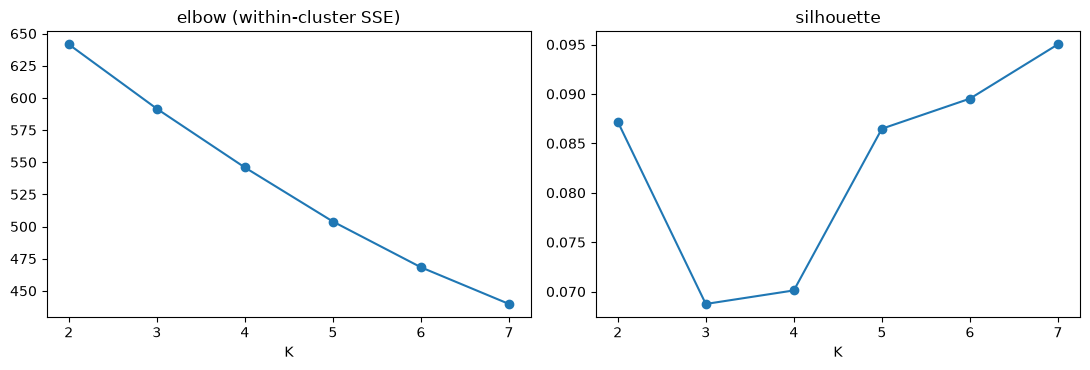

In [3]:
ks = list(range(2, 8))
inertias, silhouettes = [], []
for k in ks:
    km = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X)
    inertias.append(km.inertia_)
    silhouettes.append(silhouette_score(X, km.labels_))

fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].plot(ks, inertias, marker="o"); axes[0].set_title("elbow (within-cluster SSE)")
axes[0].set_xlabel("K")
axes[1].plot(ks, silhouettes, marker="o"); axes[1].set_title("silhouette")
axes[1].set_xlabel("K")
fig.tight_layout(); fig.savefig(FIG / "nb05_k_selection.png", dpi=130); plt.show()

## 2. External agreement: do clusters correspond to nations?

The Adjusted Rand Index is 0 for a random partition and 1 for a perfect match.
We also report the Adjusted Mutual Information. Then we permute the nation
labels to get the null distribution of ARI *for this exact clustering*: if the
observed ARI is not beyond the null, the clustering carries no nation signal.

In [4]:
rng = np.random.default_rng(42)
n_perm = 2000
rows = []
for k in ks:
    km = KMeans(n_clusters=k, n_init=50, random_state=42).fit(X)
    ari = adjusted_rand_score(labels, km.labels_)
    ami = adjusted_mutual_info_score(labels, km.labels_)
    null = np.array([adjusted_rand_score(rng.permutation(labels), km.labels_) for _ in range(n_perm)])
    p_value = (1 + (null >= ari).sum()) / (n_perm + 1)
    rows.append({"K": k, "silhouette": silhouettes[k - 2], "ARI_vs_nation": ari,
                 "AMI_vs_nation": ami, "perm_p": p_value})
results = pd.DataFrame(rows)
print(results.round(4).to_string(index=False))
results.to_csv(ROOT / "results" / "tables" / "nb05_kmeans_scores.tsv", sep="\t", index=False)

 K  silhouette  ARI_vs_nation  AMI_vs_nation  perm_p
 2      0.0872         0.0352         0.0711  0.0325
 3      0.0687         0.0783         0.1503  0.0005
 4      0.0701         0.0615         0.1146  0.0070
 5      0.0865         0.1103         0.1838  0.0005
 6      0.0895         0.0679         0.1227  0.0055
 7      0.0950         0.1288         0.2228  0.0005


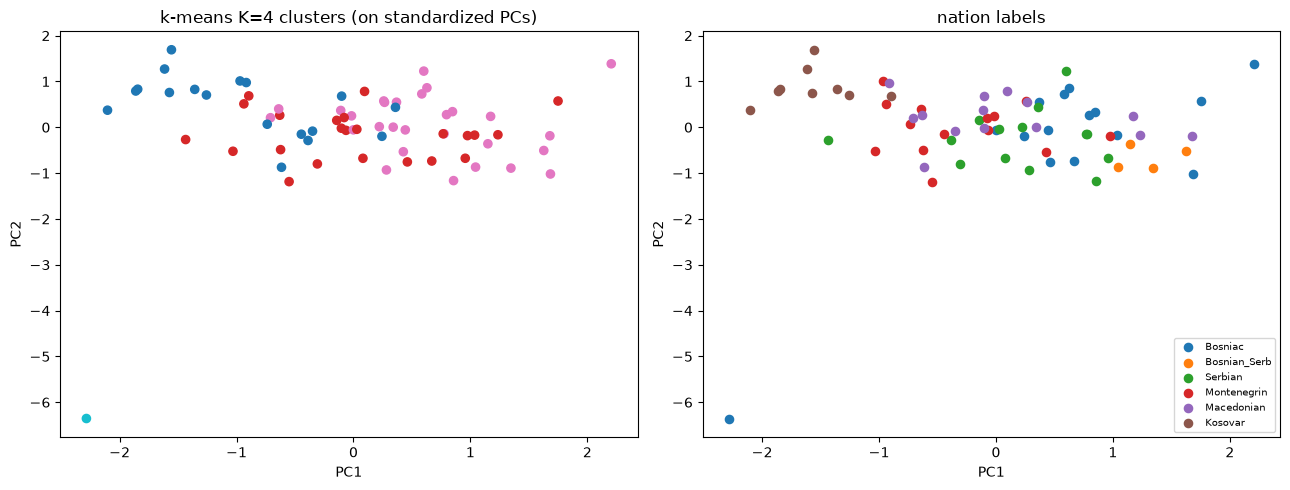

In [5]:
km4 = KMeans(n_clusters=4, n_init=50, random_state=42).fit(X)
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
axes[0].scatter(X[:, 0], X[:, 1], c=km4.labels_, cmap="tab10", s=35)
axes[0].set_title("k-means K=4 clusters (on standardized PCs)")
for group in balkan:
    sub = X[labels == group]
    axes[1].scatter(sub[:, 0], sub[:, 1], s=35, label=group)
axes[1].legend(fontsize=7); axes[1].set_title("nation labels")
for ax in axes:
    ax.set_xlabel("PC1"); ax.set_ylabel("PC2")
fig.tight_layout(); fig.savefig(FIG / "nb05_kmeans_vs_nation.png", dpi=130); plt.show()

## 3. The trap: k-means finds clusters in a pure cline

Simulate 70 individuals from exactly the same continuous admixture model as
notebook 02 (no nations, just a gradient), take the top 10 PCs, run k-means,
and compute the ARI against arbitrary "labels". The partitions look real by
internal metrics, but they are meaningless.

In [6]:
n_ind, n_snp = 70, 20000
ancestry = rng.beta(0.4, 0.4, n_ind)
p0 = rng.uniform(0.05, 0.95, n_snp)
p1 = np.clip(p0 + rng.normal(0, 0.15, n_snp), 0.01, 0.99)
freqs = (1 - ancestry[:, None]) * p0 + ancestry[:, None] * p1
G = rng.binomial(2, np.clip(freqs, 0, 1)).astype(np.float32)
Gc = G - G.mean(0, keepdims=True)
sd = Gc.std(0, keepdims=True); sd[sd == 0] = 1
U, S, _ = np.linalg.svd(Gc / sd, full_matrices=False)
X_sim = StandardScaler().fit_transform(U[:, :10] * S[:10])
fake_labels = np.array(["north", "south"] * (n_ind // 2))

km_sim = KMeans(n_clusters=4, n_init=50, random_state=42).fit(X_sim)
print("silhouette on pure cline, K=4:", round(silhouette_score(X_sim, km_sim.labels_), 3))
print("ARI of cline clusters vs fake labels:",
      round(adjusted_rand_score(fake_labels, km_sim.labels_), 3))

silhouette on pure cline, K=4: 0.212
ARI of cline clusters vs fake labels: -0.003


## Conclusions

- K-means will always produce a partition; the silhouette will often prefer a
  small K even when the data are a continuum.
- On the real data, ARI against nation labels is small and usually close to
  the permutation null. The clusters mostly reflect the leading geographic
  gradient, not nationality.
- This is why the next notebook switches from *unsupervised clustering* to
  *prediction with cross-validation*: it asks the sharper question, can we
  guess a held-out person's nation from their genotype?

## Exercises

1. Run k-means on the **unstandardized** PCs (where later PCs have smaller
   variance). How do the clusters change?
2. Replace k-means with a Gaussian mixture model and choose the number of
   components by BIC. Does it change your answer?
3. Combine the three Bosnian groups into one label and recompute ARI. Does
   merging labels increase agreement?
4. In the cline simulation, sweep the admixture parameter from U-shaped to
   uniform ancestry. When does k-means start "finding" the fake labels?

Next: `06_nation_test.ipynb`, the direct test.